<a href="https://colab.research.google.com/github/shivanvithajayam/1BF24CS127_AI_LAB/blob/main/alpha_beta_pruning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Enter tree: {'A':['B','C'],'B':['D','E'],'C':['F','G'],'D':['L1','L2'],'E':['L3','L4'],'F':['L5','L6'],'G':['L7','L8']}
Enter leaf values: 10 9 14 18 5 4 50 3

Optimal value: 10
Visited nodes: {'D', 'C', 'E', 'F', 'A', 'L3', 'B', 'L6', 'L1', 'L2', 'L5'}
Pruned nodes: {'L8', 'L4', 'G', 'L7'}


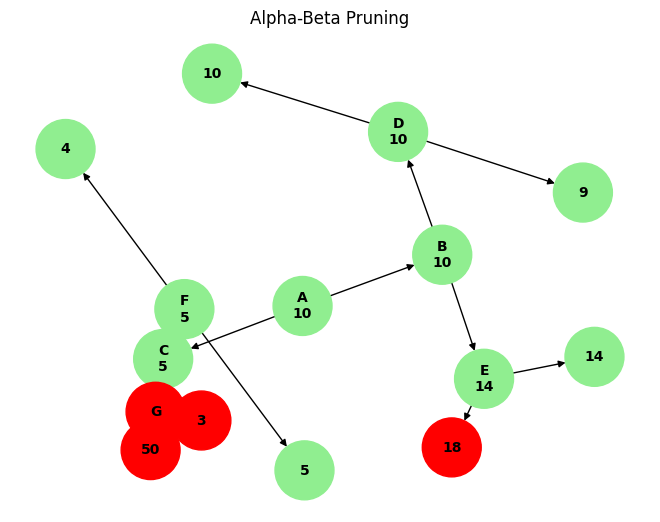

In [1]:
import networkx as nx
import matplotlib.pyplot as plt

# -------- INPUT TREE --------
tree = eval(input("Enter tree: "))

# Find leaf nodes
leaves = [c for n in tree for c in tree[n] if c not in tree]

# Input leaf values
leaf = list(map(int, input("Enter leaf values: ").split()))
leaf_values = dict(zip(leaves, leaf))

visited = set()
pruned = set()
values = {}

# -------- ALPHA BETA --------
def mark_pruned(node):
    pruned.add(node)
    for c in tree.get(node, []):
        mark_pruned(c)

def alpha_beta(node, alpha, beta, is_max):
    if node not in tree:
        visited.add(node)
        return leaf_values[node]

    visited.add(node)
    val = float('-inf') if is_max else float('inf')

    for i, child in enumerate(tree[node]):
        x = alpha_beta(child, alpha, beta, not is_max)

        if is_max:
            val = max(val, x)
            alpha = max(alpha, val)
        else:
            val = min(val, x)
            beta = min(beta, val)

        if alpha >= beta:
            for r in tree[node][i+1:]:
                mark_pruned(r)
            break

    values[node] = val
    return val

# Find root
root = next(n for n in tree if all(n not in ch for ch in tree.values()))

ans = alpha_beta(root, float('-inf'), float('inf'), True)

print("\nOptimal value:", ans)
print("Visited nodes:", visited)
print("Pruned nodes:", pruned)

# -------- DRAW GRAPH --------
G = nx.DiGraph(tree)
pos = nx.spring_layout(G, seed=2)

labels = {}
for n in G.nodes:
    if n in leaf_values:
        labels[n] = str(leaf_values[n])
    elif n in values:
        labels[n] = f"{n}\n{values[n]}"
    else:
        labels[n] = n

colors = []
for n in G.nodes:
    if n in pruned:
        colors.append("red")
    elif n in visited:
        colors.append("lightgreen")
    else:
        colors.append("lightgray")

nx.draw(
    G, pos,
    labels=labels,
    with_labels=True,
    node_color=colors,
    node_size=1800,
    font_size=10,
    font_weight="bold",
    arrows=True
)

plt.title("Alpha-Beta Pruning")
plt.axis("off")
plt.show()